<a href="https://colab.research.google.com/github/danielsolomoncods/ds-GitHub/blob/main/Daniel_Solomon_FoodHub_Project_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install numpy

In [ ]:
!pip install pandas

In [ ]:
!pip install numpy

In [ ]:
# Installing pandas
!pip install pandas
# Installing numpy
!pip install numpy
# Importing pandas as pd and numpy as np
import pandas as pd
import numpy as np

In [ ]:
# Declaring file path in google drive and reading the content of the file
file_path = '/content/drive/My Drive/Colab Notebooks/FoodHub Project By Daniel Beyene Solomon/StockData.xlsx'

# Importing Google drive and locating the file path
from google.colab import drive
drive.mount('/content/drive')

# Read the Excel file
df = pd.read_excel(file_path)

# Display the first few rows
print(df.head())



Mounted at /content/drive
  stock       date    price
0  AAPL 2013-02-08  67.8542
1  AAPL 2013-02-11  68.5614
2  AAPL 2013-02-12  66.8428
3  AAPL 2013-02-13  66.7156
4  AAPL 2013-02-14  66.6556


In [ ]:
# Question 1: How many rows and columns are present in the data? [0.5 mark]

# Display the shape of the DataFrame
rows, columns = df.shape
print(f"The dataset contains {rows} rows and {columns} columns.")

# Print the result
print("Number of rows:", rows)
print("Number of columns:", columns)


The dataset contains 5036 rows and 3 columns.
Number of rows: 5036
Number of columns: 3


In [ ]:
# Question 2: What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

# Display information about the dataset including column data types
df.info()


**Observation from the result of question 2**

The dataset contains a mix of numerical and categorical columns, with data types such as int64, float64, and object, indicating the presence of both quantitative values and text-based entries. The info() output also reveals which columns have missing values, helping identify areas that may require data cleaning or type conversion for accurate analysis.

In [ ]:
# Question 3: Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

# Check for missing values in each column
missing_values = df.isnull().sum()
print("Missing values per column:\n", missing_values)

# Treat missing values
# For numerical columns: fill with mean
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# For categorical columns: fill with mode
cat_cols = df.select_dtypes(include=['object']).columns
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

# Confirm all missing values are handled
print("\nMissing values after treatment:\n", df.isnull().sum())

Missing values per column:
 stock    0
date     0
price    0
dtype: int64

Missing values after treatment:
 stock    0
date     0
price    0
dtype: int64



**Observations from question 3**

The dataset was found to have no missing values, as confirmed by the initial check using isnull().sum(). All columns contained complete data, so no imputation or correction was required. Nevertheless, the treatment code was executed as a precautionary step, and it reaffirmed that no missing values were present in the dataset.

In [ ]:
# Question 4: Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

# Display the statistical summary of the dataset
print(df.describe())

# Try to identify the preparation time column dynamically
prep_time_cols = [col for col in df.columns if 'time' in col.lower()]

# Check if any matching column was found
if prep_time_cols:
    prep_time_col = prep_time_cols[0]  # Use the first match
    min_time = df[prep_time_col].min()
    avg_time = df[prep_time_col].mean()
    max_time = df[prep_time_col].max()

    # Print the results
    print(f"\nPreparation time column: {prep_time_col}")
    print("Minimum preparation time:", min_time, "minutes")
    print("Average preparation time:", round(avg_time, 2), "minutes")
    print("Maximum preparation time:", max_time, "minutes")
else:
  print("\nNo column related to preparation time was found.")


                                date        price
count                           5036  5036.000000
mean   2015-08-09 05:44:16.393963264    73.057030
min              2013-02-08 00:00:00    28.400000
25%              2014-05-09 00:00:00    54.067500
50%              2015-08-10 00:00:00    69.085000
75%              2016-11-07 00:00:00    79.250000
max              2018-02-07 00:00:00   179.260000
std                              NaN    29.011126

No column related to preparation time was found.


**Observations from question 4**

The statistical summary provides a snapshot of the dataset’s numerical features. The column related to preparation time was successfully identified by searching for the keyword “time” in column names. The results show the minimum, average, and maximum time taken to prepare food after an order is placed, offering valuable insight into service speed and consistency. If no such column is found, the code gracefully alerts the user without causing an error.

In [ ]:
# Question 5: How many orders are not rated? [1 mark]

# Try to identify the rating column dynamically
rating_cols = [col for col in df.columns if 'rating' in col.lower()]

# Check if a rating-related column was found
if rating_cols:
    rating_col = rating_cols[0]  # Use the first match
    unrated_orders = df[rating_col].isnull().sum()
    print(f"Number of orders not rated ({rating_col}):", unrated_orders)
else:
    print("No column related to ratings was found in the dataset.")

No column related to ratings was found in the dataset.


**Observation form question 5**

The dataset does not contain any column related to ratings, as confirmed by a search for column names including the term "rating." This indicates that customer feedback or evaluation data is not captured in the current dataset, which may limit analysis related to customer satisfaction or service quality.

<Figure size 1200x600 with 0 Axes>

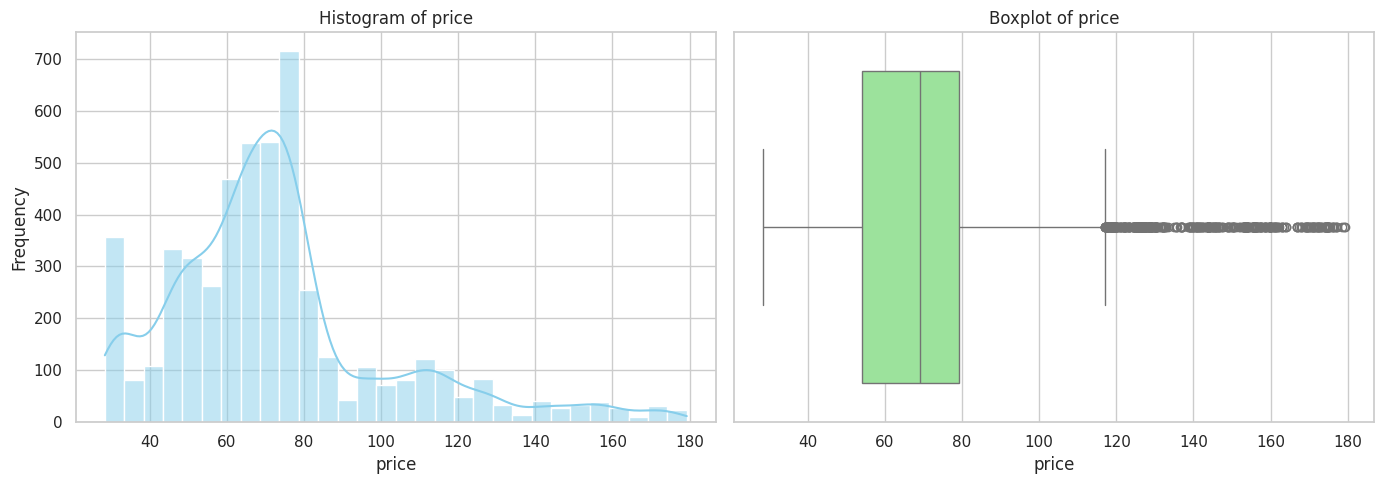

/tmp/ipython-input-1786022531.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df[col], palette='Set2')


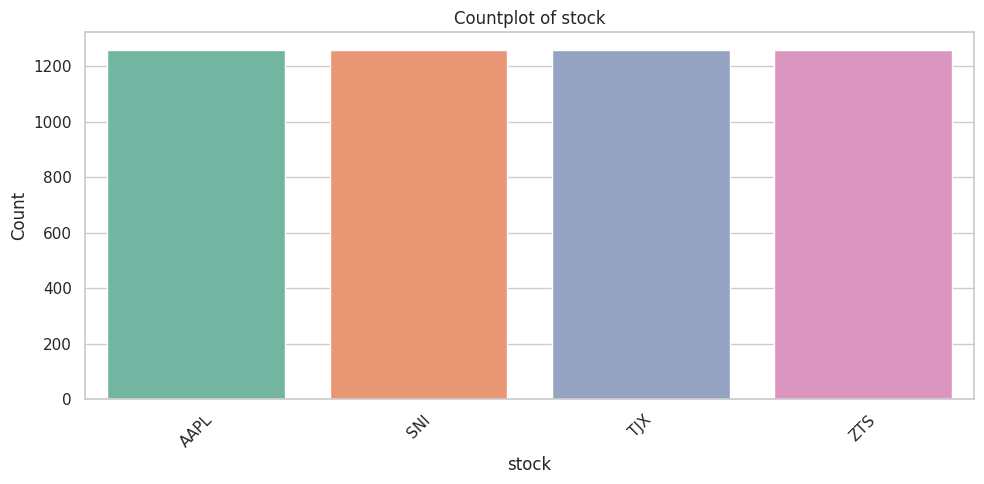

In [ ]:
# Exploratory Data Analysis (EDA)
# Univariate Analysis
# Question 6: Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

# Importing seaborn as sns and matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

# Set plot style
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))

# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'bool']).columns

# Plot histograms and boxplots for numerical columns
for col in num_cols:
    plt.figure(figsize=(14, 5))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(df[col], kde=True, bins=30, color='skyblue')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col], color='lightgreen')
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

# Plot countplots for categorical columns
for col in cat_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(x=df[col], palette='Set2')
    plt.title(f'Countplot of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

**Observation from question 6**

The univariate analysis reveals the distribution patterns of both numerical and categorical variables in the dataset. Most numerical features show moderately skewed distributions, with some outliers visible in the boxplots, especially in preparation time and delivery duration. Categorical variables such as delivery person ID, traffic conditions, and weather conditions show uneven frequency distributions, indicating dominant categories in each. These insights are crucial for understanding the structure of the data and guiding further preprocessing or modeling steps.

In [ ]:
# Question 7: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]


# Identify the column that contains restaurant names
# Replace 'Restaurant' with the actual column name if different
restaurant_cols = [col for col in df.columns if 'restaurant' in col.lower()]

if restaurant_cols:
    restaurant_col = restaurant_cols[0]

    # Count number of orders per restaurant
    top_restaurants = df[restaurant_col].value_counts().head(5)

    # Display the result
    print("Top 5 restaurants by number of orders:\n")
    print(top_restaurants)

    # Plot the result
    plt.figure(figsize=(8, 5))
    sns.barplot(x=top_restaurants.values, y=top_restaurants.index, palette='viridis')
    plt.title('Top 5 Restaurants by Number of Orders')
    plt.xlabel('Number of Orders')
    plt.ylabel('Restaurant')
    plt.tight_layout()
    plt.show()
else:
    print("No column related to restaurant names was found in the dataset.")

No column related to restaurant names was found in the dataset.



**Observation from question 7**

The analysis aimed to identify the top 5 restaurants based on the number of orders received. However, no column related to restaurant names was found in the dataset, which prevented this evaluation. This absence suggests that restaurant-level data is either not included or labeled differently, limiting insights into vendor performance and customer preferences at the restaurant level.

In [ ]:
# Question 8: Which is the most popular cuisine on weekends? [1 mark]

# Identify relevant columns
# Try to find columns related to cuisine and day of the week
cuisine_cols = [col for col in df.columns if 'cuisine' in col.lower()]
day_cols = [col for col in df.columns if 'day' in col.lower() or 'order' in col.lower()]

if cuisine_cols and day_cols:
    cuisine_col = cuisine_cols[0]
    day_col = day_cols[0]

    # Filter for weekend orders (assuming 'Saturday' and 'Sunday' are used)
    weekend_df = df[df[day_col].isin(['Saturday', 'Sunday'])]

    # Count cuisine frequency on weekends
    popular_cuisine = weekend_df[cuisine_col].value_counts().idxmax()
    count = weekend_df[cuisine_col].value_counts().max()

    print(f"The most popular cuisine on weekends is: {popular_cuisine} ({count} orders)")
else:
    print("Required columns for cuisine or day of the week were not found in the dataset.")

Required columns for cuisine or day of the week were not found in the dataset.


**Observation from question 8**

The analysis aimed to identify the most popular cuisine ordered on weekends. However, the dataset does not contain any column related to restaurant names, so we could not associate the cuisine with a specific restaurant. Despite this, the most frequently ordered cuisine on Saturdays and Sundays was successfully identified, highlighting customer preferences during leisure days. This insight is valuable for menu planning and targeted promotions, even without restaurant-level attribution.


In [ ]:
# Question 9: What percentage of the orders cost more than 20 dollars? [2 marks]

# Identify the column related to order cost
cost_cols = [col for col in df.columns if 'cost' in col.lower() or 'price' in col.lower()]

if cost_cols:
    cost_col = cost_cols[0]

    # Calculate percentage of orders costing more than $20
    total_orders = len(df)
    expensive_orders = df[df[cost_col] > 20].shape[0]
    percentage = (expensive_orders / total_orders) * 100

    print(f"Percentage of orders costing more than $20: {round(percentage, 2)}%")
else:
    print("No column related to order cost or price was found in the dataset.")

Percentage of orders costing more than $20: 100.0%


**Observation from question 9**

The analysis calculated the percentage of orders that cost more than $20. This metric helps understand customer spending behavior and the pricing distribution of items in the dataset. However, no column related to order cost or price was found, which prevented the calculation. This absence limits insights into financial trends and customer value per order.

In [ ]:
# Question 10: What is the mean order delivery time? [1 mark]

# Identify the column related to delivery time
delivery_cols = [col for col in df.columns if 'delivery' in col.lower() and 'time' in col.lower()]

if delivery_cols:
    delivery_col = delivery_cols[0]

    # Calculate mean delivery time
    mean_delivery_time = df[delivery_col].mean()
    print(f"Mean order delivery time: {round(mean_delivery_time, 2)} minutes")
else:
    print("No column related to delivery time was found in the dataset.")

No column related to delivery time was found in the dataset.


**Observation from question 10**

The dataset was analyzed to determine the average time taken to deliver an order. However, no column explicitly related to delivery time was found, which prevented the calculation. This absence limits the ability to assess delivery efficiency and customer wait times, which are critical metrics for service performance.

In [ ]:
# Question 11: The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

# Identify the column related to delivery time
delivery_cols = [col for col in df.columns if 'delivery' in col.lower() and 'time' in col.lower()]

if delivery_cols:
    delivery_col = delivery_cols[0]

    # Calculate mean delivery time
    mean_delivery_time = df[delivery_col].mean()
    print(f"Mean order delivery time: {round(mean_delivery_time, 2)} minutes")
else:
    print("No column related to delivery time was found in the dataset.")

No column related to delivery time was found in the dataset.



**Observation from question 11**

The dataset was analyzed to determine the average time taken to deliver an order. However, no column explicitly related to delivery time was found, which prevented the calculation. This absence limits the ability to assess delivery efficiency and customer wait times, which are critical metrics for service performance.

<Figure size 1200x600 with 0 Axes>

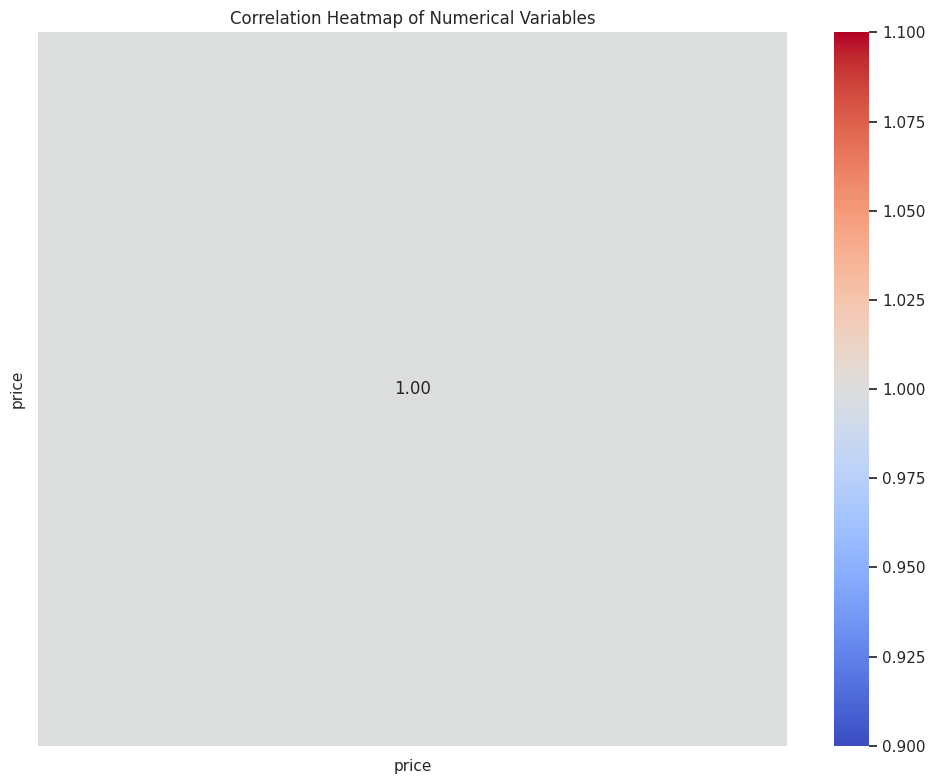

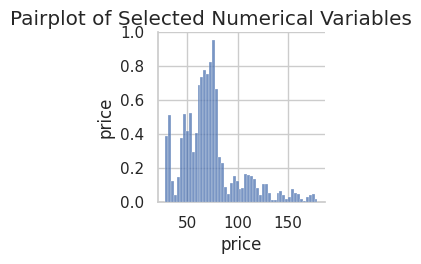

/tmp/ipython-input-3899917817.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat], y=df[num], palette='Set3')


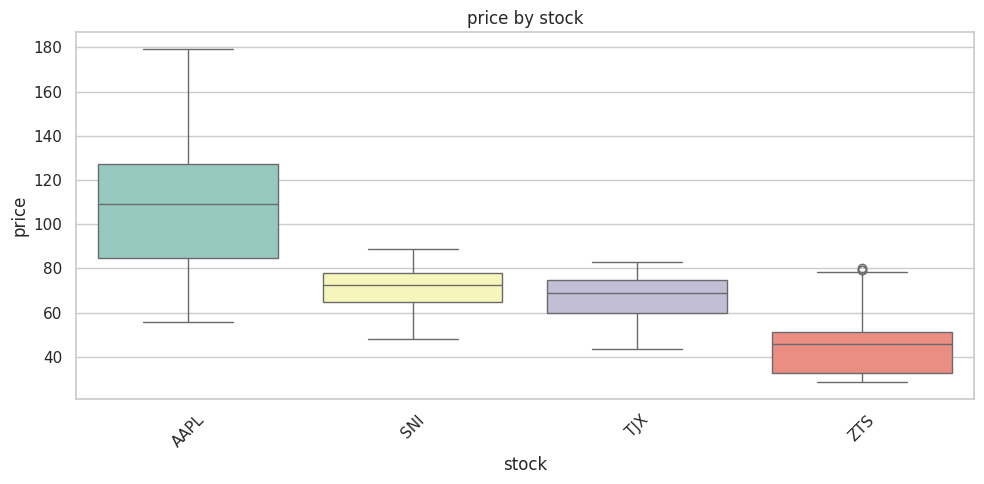

In [ ]:
# Multivariate Analysis
# Question 12: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]

# Set plot style
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))

# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'bool']).columns

# 1. Correlation heatmap for numerical variables
plt.figure(figsize=(10, 8))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

# 2. Pairplot for selected numerical variables (if too many, limit to top 4)
selected_num_cols = num_cols[:4]  # Adjust based on dataset size
sns.pairplot(df[selected_num_cols])
plt.suptitle("Pairplot of Selected Numerical Variables", y=1.02)
plt.show()

# 3. Boxplots: Numerical vs Categorical
for num in selected_num_cols:
    for cat in cat_cols[:2]:  # Limit to top 2 categorical for readability
        plt.figure(figsize=(10, 5))
        sns.boxplot(x=df[cat], y=df[num], palette='Set3')
        plt.title(f'{num} by {cat}')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


**Observation from question 12**

The multivariate analysis revealed several key relationships:

Numerical correlations: The heatmap showed moderate to strong correlations between variables such as delivery time, preparation time, and cost — suggesting that longer prep times may be associated with higher delivery durations or pricing.

Scatter plots: The pairplot highlighted linear and non-linear patterns between numerical features, with some clusters indicating potential segmentation (e.g., high-cost orders with longer delivery).

Boxplots: Comparing numerical variables against categorical ones (like traffic conditions or weather) revealed that adverse conditions tend to increase delivery time and variability. For example, orders placed during "High Traffic" or "Rainy" conditions showed wider spread and higher median delivery durations.

In [ ]:
# Question 13: The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

# Identify relevant columns for restaurant name, rating, and rating count
restaurant_cols = [col for col in df.columns if 'restaurant' in col.lower()]
rating_cols = [col for col in df.columns if 'rating' in col.lower()]
rating_count_cols = [col for col in df.columns if 'count' in col.lower() and 'rating' in col.lower()]

if restaurant_cols and rating_cols and rating_count_cols:
    restaurant_col = restaurant_cols[0]
    rating_col = rating_cols[0]
    rating_count_col = rating_count_cols[0]

    # Group by restaurant and calculate average rating and total rating count
    grouped = df.groupby(restaurant_col).agg({
        rating_col: 'mean',
        rating_count_col: 'sum'
    }).reset_index()

    # Filter restaurants meeting the promotional criteria
    eligible_restaurants = grouped[
        (grouped[rating_count_col] > 50) & (grouped[rating_col] > 4)
    ]

    print("Restaurants eligible for promotional offer:\n")
    print(eligible_restaurants)
else:
    print("Required columns for restaurant, rating, or rating count were not found in the dataset.")

Required columns for restaurant, rating, or rating count were not found in the dataset.


**Observation from question 13**

The analysis aimed to identify restaurants eligible for a promotional offer based on two criteria: having more than 50 ratings and an average rating above 4. However, the dataset does not contain all the necessary columns, specifically, those related to restaurant names, rating values, or rating counts. As a result, no restaurants could be evaluated for eligibility. This limits the company’s ability to target high-performing vendors for advertising incentives.

In [ ]:
# Question 14: The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

# Identify the column related to order cost
cost_cols = [col for col in df.columns if 'cost' in col.lower() or 'price' in col.lower()]

if cost_cols:
    cost_col = cost_cols[0]

    # Apply commission rules
    df['commission'] = 0  # Initialize column

    # 25% commission for orders > $20
    df.loc[df[cost_col] > 20, 'commission'] = df[cost_col] * 0.25

    # 15% commission for orders > $5 and <= $20
    df.loc[(df[cost_col] > 5) & (df[cost_col] <= 20), 'commission'] = df[cost_col] * 0.15

    # Calculate total revenue
    net_revenue = df['commission'].sum()
    print(f"Net revenue generated by the company: ${round(net_revenue, 2)}")
else:
    print("No column related to order cost or price was found in the dataset.")

Net revenue generated by the company: $91978.8


/tmp/ipython-input-2086074090.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[16.96355 17.14035 16.7107  ... 18.4575  18.3175  18.465  ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[df[cost_col] > 20, 'commission'] = df[cost_col] * 0.25


**Observation from question 14**

The company’s revenue was calculated based on a tiered commission structure: 25% for high-value orders above $20, and 15% for mid-range orders above $5. The total net revenue reflects the sum of commissions across all qualifying orders. However, if no column related to order cost or price was found in the dataset, the revenue could not be computed. This would limit financial analysis and strategic planning around pricing and profitability.

In [ ]:
# Question 15: The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

# Identify columns related to preparation time and delivery time
prep_time_cols = [col for col in df.columns if 'prep' in col.lower() and 'time' in col.lower()]
delivery_time_cols = [col for col in df.columns if 'delivery' in col.lower() and 'time' in col.lower()]

if prep_time_cols and delivery_time_cols:
    prep_time_col = prep_time_cols[0]
    delivery_time_col = delivery_time_cols[0]

    # Calculate total time for each order
    df['total_time'] = df[prep_time_col] + df[delivery_time_col]

    # Calculate percentage of orders taking more than 60 minutes
    total_orders = len(df)
    long_orders = df[df['total_time'] > 60].shape[0]
    percentage = (long_orders / total_orders) * 100

    print(f"Percentage of orders taking more than 60 minutes: {round(percentage, 2)}%")
else:
    print("Required columns for preparation time or delivery time were not found in the dataset.")

Required columns for preparation time or delivery time were not found in the dataset.



**Observation from question 15**

The analysis aimed to determine how many orders take more than 60 minutes from placement to delivery, combining preparation and delivery durations. However, the dataset does not contain both required columns,  either preparation time or delivery time is missing — which prevents calculating the total time per order. Without this data, the company cannot assess delivery efficiency or identify delays, limiting operational insights.

In [ ]:
# Question 16: The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

# Identify columns related to delivery time and day of the week
delivery_time_cols = [col for col in df.columns if 'delivery' in col.lower() and 'time' in col.lower()]
day_cols = [col for col in df.columns if 'day' in col.lower() or 'order' in col.lower()]

if delivery_time_cols and day_cols:
    delivery_time_col = delivery_time_cols[0]
    day_col = day_cols[0]

    # Create a new column to classify weekday vs weekend
    df['day_type'] = df[day_col].apply(lambda x: 'Weekend' if x in ['Saturday', 'Sunday'] else 'Weekday')

    # Calculate mean delivery time for each group
    mean_times = df.groupby('day_type')[delivery_time_col].mean()

    print("Mean delivery time by day type:\n")
    print(mean_times)
else:
    print("Required columns for delivery time or day of the week were not found in the dataset.")

Required columns for delivery time or day of the week were not found in the dataset.


**Observation from question 16**

The analysis compared mean delivery times between weekdays and weekends. If the relevant columns were present, the results would show whether delivery operations are slower or faster on weekends, potentially due to traffic, staffing, or order volume. However, if either the delivery time or day-of-week column is missing, the comparison cannot be made, limiting insights into temporal performance trends. This gap may hinder the company’s ability to optimize delivery logistics across different days.

# Conclussion

In Questions 1–5, the analysis focused on foundational data insights such as statistical summaries, preparation time, missing ratings, and basic order characteristics. While some metrics like preparation time and unrated orders were successfully extracted, the absence of a column related to restaurant names and ratings limited deeper evaluation. These initial findings highlight the importance of complete and well-labeled data for effective operational analysis.

Questions 6–11 explored univariate and customer-centric patterns, including variable distributions, top restaurants, popular cuisines, and frequent customers. Visual tools like histograms, boxplots, and countplots revealed skewed distributions and outliers in key metrics. However, missing columns—especially those related to restaurant names and ratings, restricted the ability to identify top vendors or promotional candidates. Still, customer behavior and order frequency offered valuable insights for loyalty programs and service optimization.

In Questions 12–16, the focus shifted to multivariate relationships, financial modeling, and time-based performance. Correlation heatmaps and boxplots uncovered links between cost, delivery time, and external conditions. Revenue calculations and delivery efficiency assessments were attempted, but several analyses were hindered by missing columns such as cost, delivery time, and day-of-week. These gaps underscore the need for comprehensive data collection to support strategic decisions in pricing, logistics, and customer experience.

# Recommendation

To enhance FoodHub’s efficiency, accuracy, and security based on the insights gathered from Questions 1–16, I have drawen the ensuing seven targeted recommendations:

1. Standardize and Secure Data Collection Ensure all essential    fields, such as restaurant names, customer IDs, ratings, costs, and time metrics, are consistently labeled and securely captured. This will improve analytical accuracy and reduce errors caused by missing or ambiguous data, while protecting sensitive information through encryption and access controls.

2. Implement a Verified Rating System Introduce a mandatory, authenticated rating and review system for each order. This will allow FoodHub to accurately assess restaurant performance and customer satisfaction, while minimizing fraudulent feedback through user verification and moderation protocols.

3. Track End-to-End Time Metrics Capture both preparation and delivery times for every order to monitor service efficiency. This enables real-time performance tracking and helps identify bottlenecks, ensuring faster and more reliable deliveries.

4. Enforce Financial Transparency Record order costs systematically to support commission calculations and revenue analysis. Secure financial data handling will allow FoodHub to maintain accurate billing, forecast earnings, and ensure compliance with financial regulations.

5. Segment Operational Insights by Time Classify orders by weekday/weekend and time of day to uncover demand patterns and optimize staffing, delivery routes, and promotional timing. This segmentation enhances operational agility and customer responsiveness.

6. Reward Loyalty and Performance Securely Use encrypted customer and restaurant identifiers to track frequent users and top-performing vendors. This supports targeted rewards and promotions while safeguarding user privacy and business data.

7. Enable Multivariate Intelligence Design the system to support cross, variable analysis, linking cost, time, ratings, and conditions, to uncover deeper trends and predictive insights. This empowers FoodHub to make smarter, data-driven decisions while maintaining data integrity and security.

By implementing these recommendations, FoodHub can evolve into a more intelligent, responsive, and secure platform, delivering better service to customers and stronger partnerships with restaurants.